# EDA

## Biblioteki

In [1]:
import os
import json
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

## Ogólne spojrzenie na zebrane dane

In [2]:
# Ścieżka do folderu, w którym są wszystkie kategorie
base_path = "../data/training_set"
recordings_base = r"D:\MGR\Master\recordings"
metadata_base_dir = "../data/metadata"

In [3]:
# Lista folderów (kategorii)
categories = [
    d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))
]

# Zliczamy liczbę plików w każdym folderze
data = []
for category in categories:
    folder_path = os.path.join(base_path, category)
    file_count = len(
        [
            f
            for f in os.listdir(folder_path)
            if os.path.isfile(os.path.join(folder_path, f))
        ]
    )
    data.append({"category": category, "file_count": file_count})

# Tworzymy DataFrame
df = pd.DataFrame(data)

# Podgląd
df

,category,file_count
0,city_daylight,6044
1,city_daylight_rain,958
2,city_night,924
3,city_night_rain,378
4,highway_daylight,1393
5,highway_daylight_rain,336
6,highway_night,238
7,highway_night_rain,42
8,mountain_roads_daylight,819
9,mountain_roads_daylight_rain,151


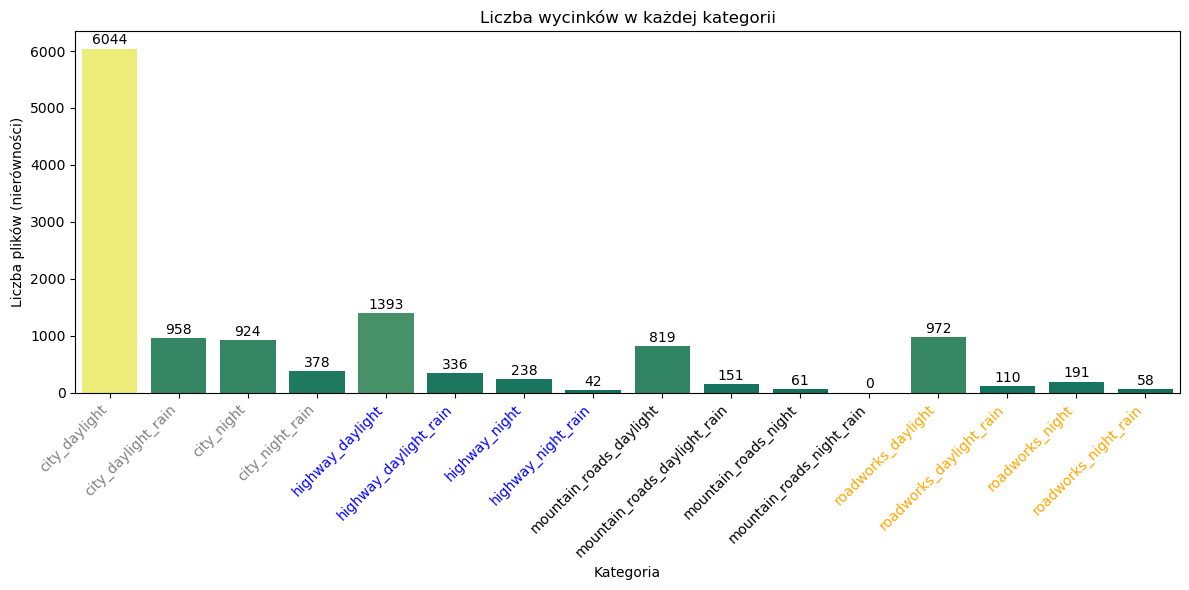

In [4]:
prefix_colors = {
    "city": "grey",
    "highway": "blue",
    "mountain_roads": "green",
    "roadworks": "orange",
}

df["prefix"] = df["category"].apply(lambda x: x.split("_")[0])

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df,
    x="category",
    y="file_count",
    hue="file_count",
    palette="summer",
    legend=False,
)
ax.set(
    title="Liczba wycinków w każdej kategorii",
    xlabel="Kategoria",
    ylabel="Liczba plików (nierówności)",
)

# Pokoloruj xtick labels na podstawie prefixu
xtick_labels = ax.get_xticklabels()
for label in xtick_labels:
    category = label.get_text()
    prefix = category.split("_")[0]
    label.set_color(prefix_colors.get(prefix, "black"))  # domyślny kolor to czarny

plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, label_type="edge", padding=1)

plt.tight_layout()
plt.show()

In [5]:
df["file_count"].sum()

np.int64(12675)

## Średnia liczba dziur na godzinę w każdej kategorii

In [6]:
avg_potholes_per_hour = df["file_count"].sum() * 60 / 2988
avg_potholes_per_hour

np.float64(254.51807228915663)

In [7]:
categories = [
    "city_daylight",
    "city_daylight_rain",
    "city_night",
    "city_night_rain",
    "highway_daylight",
    "highway_daylight_rain",
    "highway_night",
    "highway_night_rain",
    "mountain_roads_daylight",
    "mountain_roads_daylight_rain",
    "mountain_roads_night",
    "mountain_roads_night_rain",
    "roadworks_daylight",
    "roadworks_daylight_rain",
    "roadworks_night",
    "roadworks_night_rain",
]

data = []

for category in categories:
    # Liczba plików .jpg (wycinków) w training_set
    jpg_dir = os.path.join(base_path, category)
    jpg_count = len([f for f in os.listdir(jpg_dir) if f.endswith(".jpg")])

    # Liczba nagrań .mp4 (każde to 1 minuta)
    mp4_dir = os.path.join(recordings_base, category, "mp4")
    mp4_count = len([f for f in os.listdir(mp4_dir) if f.endswith(".mp4")])

    # Obliczenie średniej liczby dziur na godzinę
    total_minutes = mp4_count  # każde nagranie to 1 minuta
    hours = total_minutes / 60
    potholes_per_hour = jpg_count / hours if hours > 0 else 0

    data.append(
        {
            "category": category,
            "jpg_count": jpg_count,
            "video_count": mp4_count,
            "potholes_per_hour": potholes_per_hour,
        }
    )

df = pd.DataFrame(data)
df = df.sort_values("potholes_per_hour", ascending=False)

# Wyświetlenie tabeli
df.style.format({"potholes_per_hour": "{:.2f}"})

,category,jpg_count,video_count,potholes_per_hour
9,mountain_roads_daylight_rain,151,8,1132.50
8,mountain_roads_daylight,819,48,1023.75
1,city_daylight_rain,958,97,592.58
0,city_daylight,6044,885,409.76
12,roadworks_daylight,972,166,351.33
2,city_night,924,181,306.30
3,city_night_rain,378,80,283.50
10,mountain_roads_night,61,14,261.43
13,roadworks_daylight_rain,110,30,220.00
15,roadworks_night_rain,58,16,217.50


In [8]:
# Zakładamy, że df zawiera kolumny: category, potholes_per_hour

# Dodaj kolumnę z prefixem (grupa kategorii)
df["road_type"] = df["category"].apply(lambda x: x.split("_")[0])
df["road_type"] = df["road_type"].replace("mountain", "mountain_roads")

# Zgrupuj i policz średnią dziur na godzinę
grouped_avg = df.groupby("road_type")["potholes_per_hour"].mean().reset_index()

# Filtruj tylko interesujące nas prefixy
target_prefixes = ["mountain_roads", "city", "roadworks", "highway"]
grouped_avg = grouped_avg[grouped_avg["road_type"].isin(target_prefixes)]

# Zaokrągl i posortuj
grouped_avg["potholes_per_hour"] = grouped_avg["potholes_per_hour"].round(2)
grouped_avg = grouped_avg.sort_values("potholes_per_hour", ascending=False)

grouped_avg

,road_type,potholes_per_hour
2,mountain_roads,604.42
0,city,398.03
3,roadworks,250.26
1,highway,92.51


In [9]:
# Funkcja do ekstrakcji warunków pogodowych z nazwy kategorii
def extract_weather(category_name):
    if "daylight_rain" in category_name:
        return "daylight_rain"
    elif "night_rain" in category_name:
        return "night_rain"
    elif "daylight" in category_name:
        return "daylight"
    elif "night" in category_name:
        return "night"
    return "unknown"


# Dodanie kolumny weather
df["weather"] = df["category"].apply(extract_weather)

# Grupowanie po warunkach pogodowych
weather_avg = df.groupby("weather")["potholes_per_hour"].mean().reset_index()

# Posortuj dla czytelności
weather_avg = weather_avg.sort_values("potholes_per_hour", ascending=False)

weather_avg

,weather,potholes_per_hour
1,daylight_rain,523.328153
0,daylight,467.952479
2,night,207.691910
3,night_rain,146.250000


### Korelacja między średnią liczbą znalezionych dziur w ciągu godziny a pogodą oraz rodzajem drogi

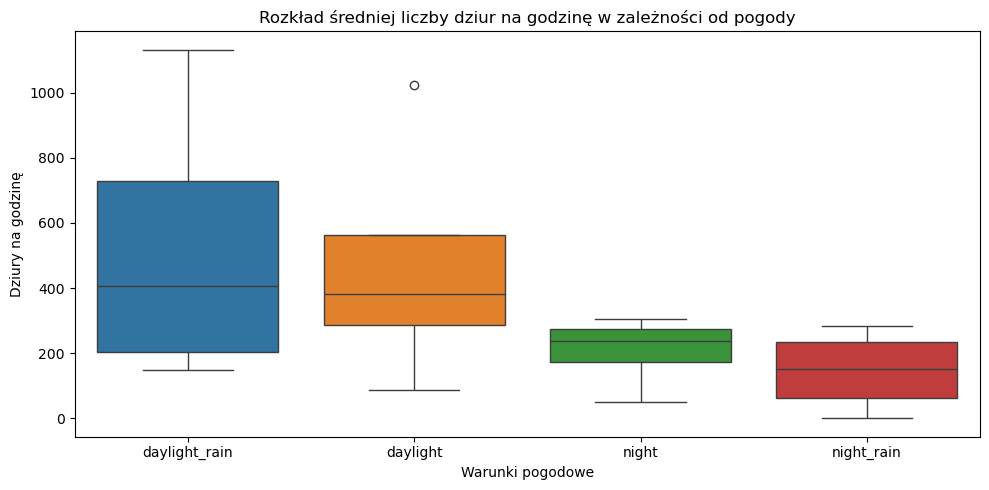

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="weather", y="potholes_per_hour", hue="weather", legend=False)
plt.title("Rozkład średniej liczby dziur na godzinę w zależności od pogody")
plt.xlabel("Warunki pogodowe")
plt.ylabel("Dziury na godzinę")
plt.tight_layout()
plt.show()

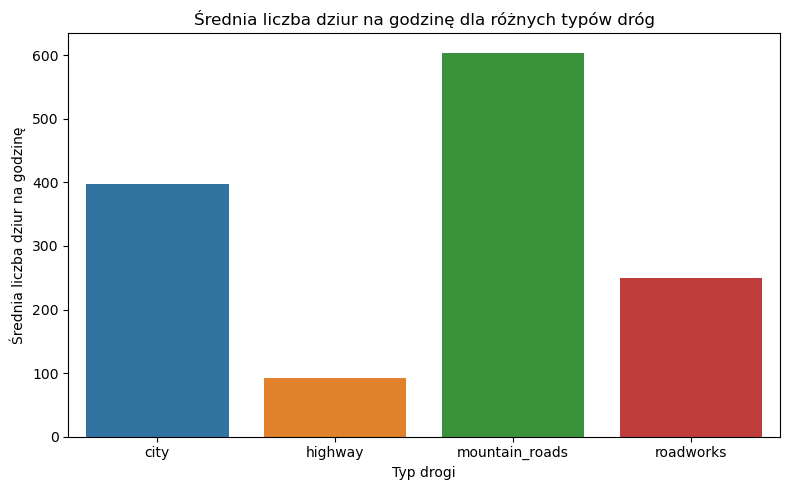

In [11]:
prefix_avg = df.groupby("road_type")["potholes_per_hour"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=prefix_avg, x="road_type", y="potholes_per_hour", hue="road_type", legend=False
)
plt.title("Średnia liczba dziur na godzinę dla różnych typów dróg")
plt.xlabel("Typ drogi")
plt.ylabel("Średnia liczba dziur na godzinę")
plt.tight_layout()
plt.show()

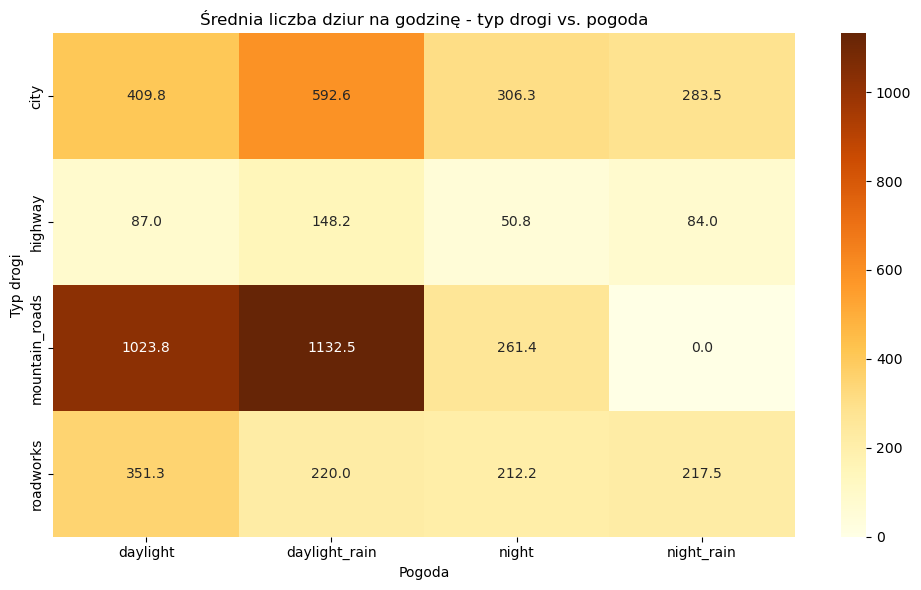

In [12]:
pivot_df = df.pivot_table(
    index="road_type", columns="weather", values="potholes_per_hour", aggfunc="mean"
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_df, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia liczba dziur na godzinę - typ drogi vs. pogoda")
plt.xlabel("Pogoda")
plt.ylabel("Typ drogi")
plt.tight_layout()
plt.show()

🔍 Pearson vs Spearman
Cecha	                        Pearson	                        Spearman
Typ korelacji	                liniowa	                        monotoniczna (rosnąca/malejąca, niekoniecznie liniowo)
Zakłada rozkład normalny?	    ✅ Tak (dla sensownych wniosków)	❌ Nie
Wrażliwa na wartości odstające?	✅ Tak	                        ❌ Mniej
Nadaje się do danych liczbowych	✅ Tak	                        ✅ Tak
Nadaje się do rang/kategorii	❌ Nie	                        ✅ Tak (rangi, porządek)

🔎 W Twoim przypadku:
dziury_na_godzine to wartość liczbowa (ciągła)

prefix i weather są kategoryczne (nienumeryczne, nieliniowe)

👉 Zalecam Spearmana – bo mierzy ogólną zależność monotoniczną i działa dobrze z rangami lub przekształconymi kategoriami.

In [13]:
# Zakoduj prefix i weather jako liczby
weather_order = {
    "daylight": 1,
    "daylight_rain": 2,
    "night": 3,
    "night_rain": 4,
}

df["weather_num"] = df["weather"].map(weather_order)

road_type_order = {
    "highway": 1,
    "roadworks": 2,
    "city": 3,
    "mountain_roads": 4,
}

df["weather_num"] = df["weather"].map(weather_order)
df["road_type_num"] = df["road_type"].map(road_type_order)
df

,category,jpg_count,video_count,potholes_per_hour,road_type,weather,weather_num,road_type_num
9,mountain_roads_daylight_rain,151,8,1132.500000,mountain_roads,daylight_rain,2,4
8,mountain_roads_daylight,819,48,1023.750000,mountain_roads,daylight,1,4
1,city_daylight_rain,958,97,592.577320,city,daylight_rain,2,3
0,city_daylight,6044,885,409.762712,city,daylight,1,3
12,roadworks_daylight,972,166,351.325301,roadworks,daylight,1,2
2,city_night,924,181,306.298343,city,night,3,3
3,city_night_rain,378,80,283.500000,city,night_rain,4,3
10,mountain_roads_night,61,14,261.428571,mountain_roads,night,3,4
13,roadworks_daylight_rain,110,30,220.000000,roadworks,daylight_rain,2,2
15,roadworks_night_rain,58,16,217.500000,roadworks,night_rain,4,2


In [14]:
# Korelacja Spearmana
corr_road_type, pval_road_type = spearmanr(df["road_type_num"], df["potholes_per_hour"])
corr_weather, pval_weather = spearmanr(df["weather_num"], df["potholes_per_hour"])

print(
    f"Korelacja Spearmana: typ drogi vs dziury/h = {corr_road_type:.2f}, p-value = {pval_road_type:.4f}"
)
print(
    f"Korelacja Spearmana: pogoda vs dziury/h = {corr_weather:.2f}, p-value = {pval_weather:.4f}"
)

Korelacja Spearmana: typ drogi vs dziury/h = 0.58, p-value = 0.0180
Korelacja Spearmana: pogoda vs dziury/h = -0.51, p-value = 0.0439


📌 Interpretacja:
Korelacja blisko 1 lub -1 oznacza silną zależność (odpowiednio dodatnią lub ujemną)

p-value < 0.05 ⇒ statystycznie istotna korelacja

✅ 1. Korelacja Spearmana: typ drogi vs dziury/h = +0.58, p = 0.0180
Co to oznacza?
Dodatnia korelacja (0.58): im „wyższy” kod przypisany typowi drogi, tym więcej dziur na godzinę.

p-value < 0.05 → wynik jest statystycznie istotny (czyli nieprzypadkowy).

Wynik sugeruje, że:
- Na bardziej „problematycznych” typach dróg (np. górskich, miejskich) wykrywa się więcej dziur.
- Jest to zgodne z intuicją – np. górskie i miejskie drogi to miejsca, gdzie realnie może być więcej uszkodzeń. Logicznie, także remonty powinny mieć więcej uszkodzeń, jednakże w przypadku zebranych danych niemal 100% robót drogowych występowało na autostradach, w związku z czym liczba nierówności była tam ograniczona, a nagrania charakteryzowały się jedynie większą liczbą pachołków/słupków ostrzegawczych oraz wolniejszym ruchem.

🌧️ 2. Korelacja Spearmana: pogoda vs dziury/h = –0.51, p = 0.0439
Co to oznacza?
Ujemna korelacja (–0.51): im gorsze warunki pogodowe, tym mniej dziur na godzinę.

p-value < 0.05 → również statystycznie istotne.

Wynik sugeruje, że:
- W trudniejszych warunkach (noc, deszcz) wykrywa się mniej dziur.

Może to oznaczać:
- słabszą widoczność, co utrudnia oznaczanie dziur,
- problemy techniczne (kamera nie widzi dobrze),
- lub realnie mniej dziur, np. bo nagrywa się inne trasy nocą.

## Analiza wielkości dziur

Średnia wielkość dla każdego nagrania!

In [15]:
data_list = []

for category in os.listdir(metadata_base_dir):
    category_path = os.path.join(metadata_base_dir, category)
    if os.path.isdir(category_path):
        for file in os.listdir(category_path):
            file_path = os.path.join(category_path, file)
            with open(file_path, "r", encoding="utf-8") as f:
                json_data = json.load(f)

                # road_type wyliczamy z category (nazwa folderu)
                road_type = category.split("_")[0]
                if road_type == "mountain":
                    road_type = "mountain_roads"

                for key, entry in json_data["metadata"].items():
                    x, y, w, h = entry["xy"][1:]
                    x1, y1 = x, y
                    x2, y2 = x + w, y + h
                    w_val = x2 - x1
                    h_val = y2 - y1

                    data_list.append({"road_type": road_type, "w": w_val, "h": h_val})

df_meta = pd.DataFrame(data_list)

In [16]:
mean_sizes = df_meta.groupby("road_type")[["w", "h"]].mean().reset_index()

mean_sizes

,road_type,w,h
0,city,161.278931,58.714255
1,highway,366.634911,64.091297
2,mountain_roads,166.031775,108.272173
3,roadworks,192.380821,79.025807


In [17]:
road_type_order = {
    "highway": 1,
    "roadworks": 2,
    "city": 3,
    "mountain_roads": 4,
}

df_meta["road_type_num"] = df_meta["road_type"].map(road_type_order)

In [18]:
# Spearman dla szerokości
corr_w, pval_w = spearmanr(df_meta["road_type_num"], df_meta["w"])
print(
    f"Korelacja Spearmana (road_type vs szerokość w): {corr_w:.3f}, p-value = {pval_w:.4f}"
)

# Spearman dla wysokości
corr_h, pval_h = spearmanr(df_meta["road_type_num"], df_meta["h"])
print(
    f"Korelacja Spearmana (road_type vs wysokość h): {corr_h:.3f}, p-value = {pval_h:.4f}"
)

Korelacja Spearmana (road_type vs szerokość w): -0.261, p-value = 0.0000
Korelacja Spearmana (road_type vs wysokość h): 0.002, p-value = 0.8153


1. Korelacja dla szerokości (w):
- Wartość korelacji wynosi -0.261, co oznacza słabą do umiarkowanej ujemną zależność monotoniczną między numerem typu drogi a szerokością dziur.
- Ponieważ wyższe wartości road_type_num to bardziej „górskie” i miejskie drogi (od autostrad do górskich), ujemny znak oznacza, że w miarę przechodzenia od autostrady (1) do dróg górskich (4) szerokość dziur ma tendencję do zmniejszania się. Jest to spójne z własnymi obserwacjami, w czasie których zauważono, że na autostradach przeważają poprzeczne podłużne nierówności (np. dylatacje), a bardziej typowe wyrwy kształtem przypominające koła (w przypadku przygotowanych wycinków - kwadraty) zdarzają się bardzo rzadko.
- P-value = 0.0000 wskazuje, że ta korelacja jest statystycznie istotna, czyli jest mało prawdopodobne, że wynik jest efektem przypadku.

2. Korelacja dla wysokości (h):
- Wartość korelacji to 0.002, bardzo bliska zeru, co oznacza brak monotonicznej zależności między typem drogi a wysokością dziur.
- P-value = 0.8153 jest duże, więc nie można uznać tej zależności za istotną statystycznie.

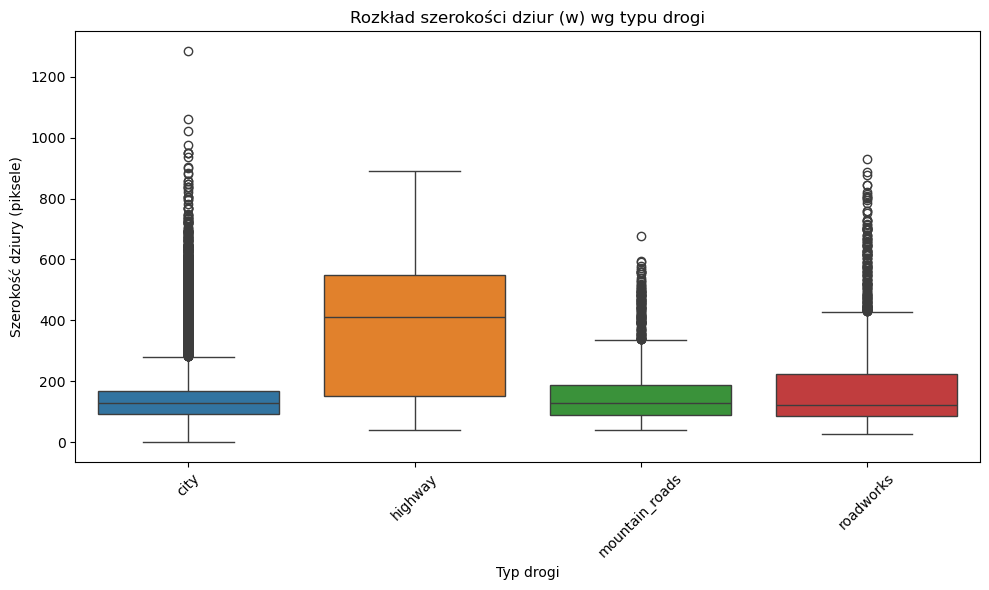

In [19]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_meta, x="road_type", y="w", hue="road_type", legend=False)
plt.title("Rozkład szerokości dziur (w) wg typu drogi")
plt.xlabel("Typ drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

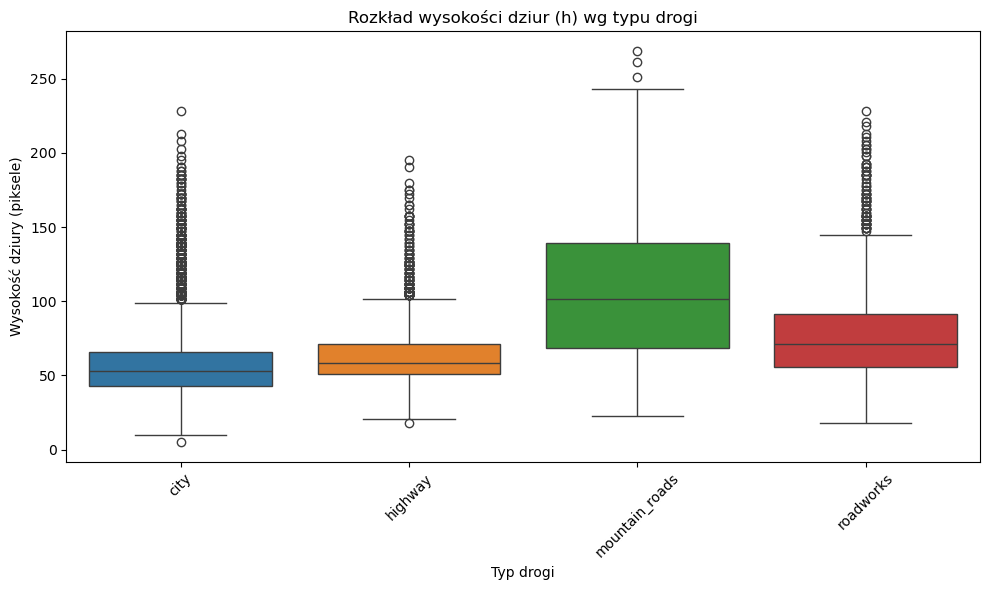

In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_meta, x="road_type", y="h", hue="road_type", legend=False)
plt.title("Rozkład wysokości dziur (h) wg typu drogi")
plt.xlabel("Typ drogi")
plt.ylabel("Wysokość dziury (piksele)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

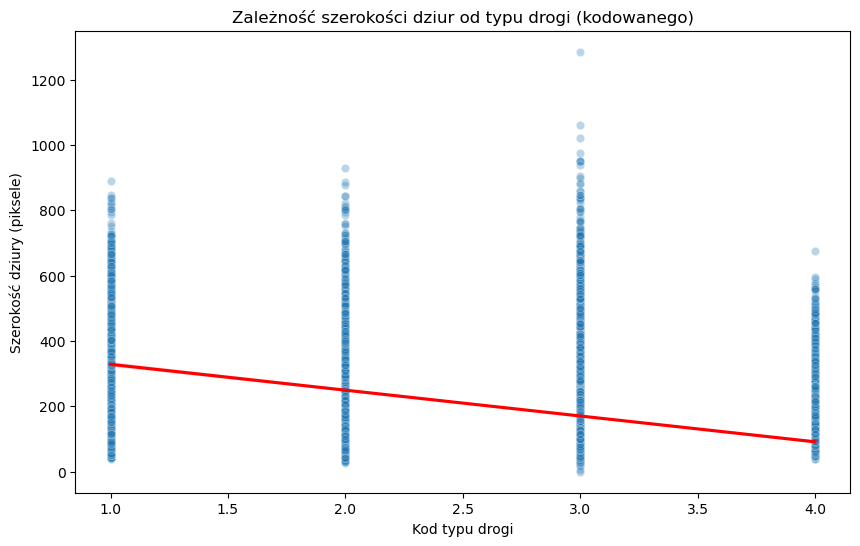

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_meta, x="road_type_num", y="w", alpha=0.3)
sns.regplot(data=df_meta, x="road_type_num", y="w", scatter=False, color="red")
plt.title("Zależność szerokości dziur od typu drogi (kodowanego)")
plt.xlabel("Kod typu drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.show()

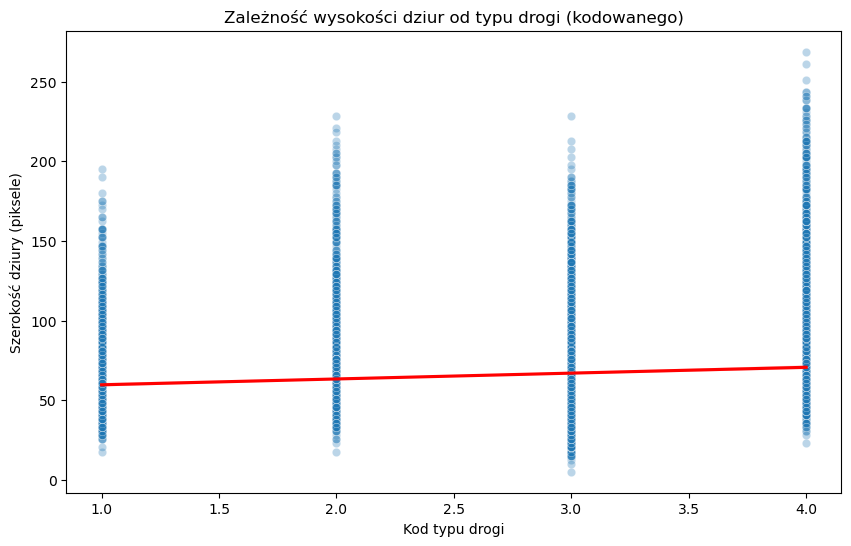

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_meta, x="road_type_num", y="h", alpha=0.3)
sns.regplot(data=df_meta, x="road_type_num", y="h", scatter=False, color="red")
plt.title("Zależność wysokości dziur od typu drogi (kodowanego)")
plt.xlabel("Kod typu drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.show()

## Analiza wielowymiarowa - wielkość dziur i częstość ich występowania

In [23]:
df
df_meta

,road_type,w,h,road_type_num
0,city,192.676,101.409,3
1,city,152.113,68.450,3
2,city,950.704,68.450,3
3,city,1285.352,86.197,3
4,city,121.690,60.845,3
...,...,...,...,...
12705,roadworks,109.015,63.380,2
12706,roadworks,45.633,32.958,2
12707,roadworks,43.098,32.958,2
12708,roadworks,65.915,81.127,2


In [ ]:
# 1. Agregacja df_meta - średnia szerokość i wysokość dziur dla każdego rodzaju drogi
agg_meta = df_meta.groupby("road_type")[["w", "h"]].mean().reset_index()
agg_meta = agg_meta.rename(columns={"w": "mean_width", "h": "mean_height"})
agg_meta
# 2. Łączenie z df (jeśli w df jest kolumna 'road_type')
df_merged = df.merge(agg_meta, on="road_type", how="left")

# Teraz df_merged zawiera kolumny: potholes_per_hour, mean_width, mean_height itp.
df_merged

,category,jpg_count,video_count,potholes_per_hour,road_type,weather,weather_num,road_type_num,mean_width,mean_height
0,mountain_roads_daylight_rain,151,8,1132.500000,mountain_roads,daylight_rain,2,4,166.031775,108.272173
1,mountain_roads_daylight,819,48,1023.750000,mountain_roads,daylight,1,4,166.031775,108.272173
2,city_daylight_rain,958,97,592.577320,city,daylight_rain,2,3,161.278931,58.714255
3,city_daylight,6044,885,409.762712,city,daylight,1,3,161.278931,58.714255
4,roadworks_daylight,972,166,351.325301,roadworks,daylight,1,2,192.380821,79.025807
5,city_night,924,181,306.298343,city,night,3,3,161.278931,58.714255
6,city_night_rain,378,80,283.500000,city,night_rain,4,3,161.278931,58.714255
7,mountain_roads_night,61,14,261.428571,mountain_roads,night,3,4,166.031775,108.272173
8,roadworks_daylight_rain,110,30,220.000000,roadworks,daylight_rain,2,2,192.380821,79.025807
9,roadworks_night_rain,58,16,217.500000,roadworks,night_rain,4,2,192.380821,79.025807


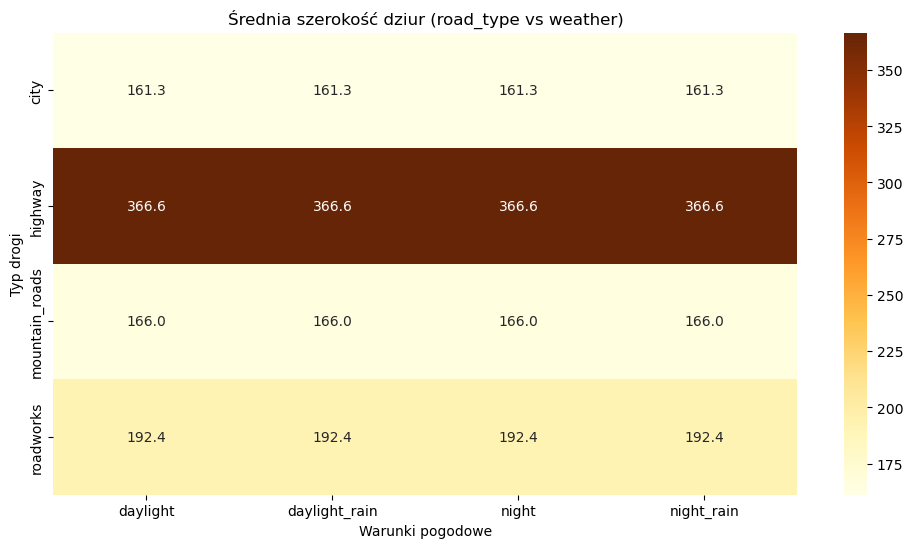

In [ ]:
# 5. Heatmapa średniej szerokości dziur (średnia szerokość zależy tylko od road_type, więc powtarza się dla warunków pogodowych)
plt.figure(figsize=(12, 6))
heatmap_width = df_merged.pivot(
    index="road_type", columns="weather", values="mean_width"
)
sns.heatmap(heatmap_width, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia szerokość dziur (road_type vs weather)")
plt.ylabel("Typ drogi")
plt.xlabel("Warunki pogodowe")
plt.show()

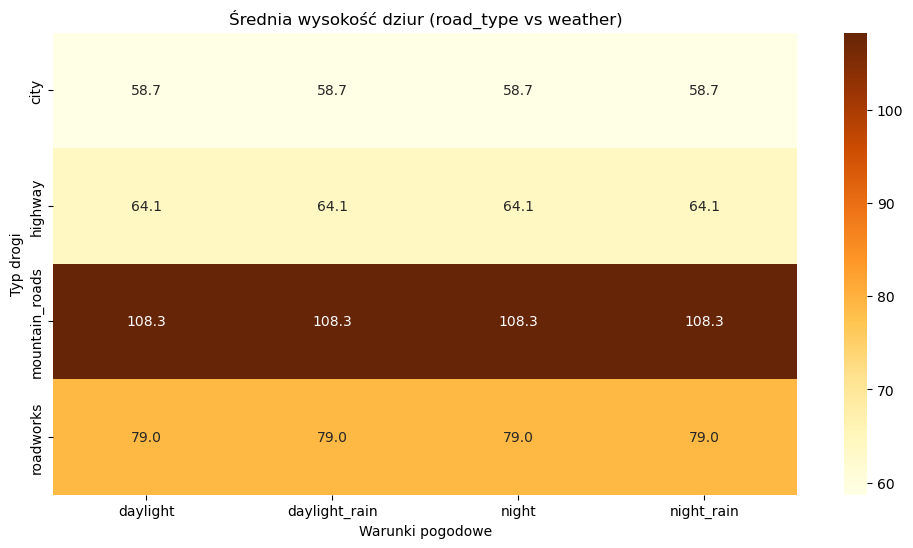

In [ ]:
# 6. Heatmapa średniej wysokości dziur
plt.figure(figsize=(12, 6))
heatmap_height = df_merged.pivot(
    index="road_type", columns="weather", values="mean_height"
)
sns.heatmap(heatmap_height, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia wysokość dziur (road_type vs weather)")
plt.ylabel("Typ drogi")
plt.xlabel("Warunki pogodowe")
plt.show()

In [ ]:
# 7. Interaktywny wykres 3D (plotly)
fig = px.scatter_3d(
    df_merged,
    x="mean_width",
    y="mean_height",
    z="potholes_per_hour",
    color="road_type",
    symbol="weather",
    size="potholes_per_hour",
    hover_data=["road_type", "weather", "category"],
    title="Średnia liczba dziur na godzinę i rozmiary dziur (3D)",
)
fig.show()